In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path = r"C:\BEAT-FINAL-PROJECT\Data\Cleaned\Spotify_Dataset_Cleaned.xlsx"

users = pd.read_excel(file_path, sheet_name="Users")
artists = pd.read_excel(file_path, sheet_name="Artists")
songs = pd.read_excel(file_path, sheet_name="Songs")
playlists = pd.read_excel(file_path, sheet_name="Playlists")
streams = pd.read_excel(file_path, sheet_name="Streams")

In [3]:
print("Users:", users.shape)
print("Artists:", artists.shape)
print("Songs:", songs.shape)
print("Playlists:", playlists.shape)
print("Streams:", streams.shape)

Users: (1000, 4)
Artists: (600, 3)
Songs: (5000, 4)
Playlists: (800, 3)
Streams: (20000, 4)


                                                                  Business Questions


User Analysis

1. Which country has the highest number of users?

In [11]:
users_by_country = (
    users["Country"]
    .value_counts()
    .reset_index()
)

users_by_country.columns = ["Country", "User_Count"]

highest_country = users_by_country.iloc[0]["Country"]

print(users_by_country)
print("Highest number of users:",highest_country)

   Country  User_Count
0   Brazil         181
1    India         178
2       UK         168
3   Canada         162
4      USA         161
5  Germany         150
Highest number of users: Brazil


2.What is the average age of Spotify users? 

In [17]:
average_age = users["Age"].mean()

print("Average age of Spotify users:", round(average_age))

Average age of Spotify users: 39


3. Which age group listens the most music? 


In [19]:
#Merge Users and Streams

user_streams = streams.merge(
    users[["User_ID", "Age"]],
    on="User_ID",
    how="left"
)

# Create age groups

bins = [18, 25, 35, 45, 55, 60]
labels = ["18-24", "25-34", "35-44", "45-54", "55-59"]

user_streams["Age_Group"] = pd.cut(
    user_streams["Age"],
    bins=bins,
    labels=labels,
    right=False
)

In [20]:
user_streams["Age_Group"].value_counts().sort_index()

Age_Group
18-24    3657
25-34    3942
35-44    5171
45-54    4805
55-59    2425
Name: count, dtype: int64

In [21]:
# Calculate total listening minutes by age group

listening_by_age = (
    user_streams
    .groupby("Age_Group", observed=True)["Minutes_Listened"]
    .sum()
    .sort_values(ascending=False)
)

print(listening_by_age)

Age_Group
35-44    25622
45-54    24011
25-34    19687
18-24    18316
55-59    12228
Name: Minutes_Listened, dtype: int64


In [22]:
top_age_group = listening_by_age.idxmax()
top_listening = listening_by_age.max()

print("Age group that listens the most:", top_age_group)
print("Total listening minutes:", top_listening)

Age group that listens the most: 35-44
Total listening minutes: 25622


What percentage of users are Premium subscribers?

In [23]:
premium_users = (users["Subscription"] == "Premium").sum()

print("Premium users:", premium_users)

Premium users: 492


In [24]:
premium_percentage = (
    premium_users / len(users)
) * 100

print("Percentage of Premium users:", round(premium_percentage, 2), "%")

Percentage of Premium users: 49.2 %


Artist Analysis


5. Which artists have the highest number of songs? 

In [25]:
# Count songs for each artist

songs_by_artist = (
    songs["Artist_ID"]
    .value_counts()
    .reset_index()
)

songs_by_artist.columns = ["Artist_ID", "Song_Count"]



In [26]:
songs_by_artist = songs_by_artist.merge(
    artists[["Artist_ID", "Artist_Name"]],
    on="Artist_ID",
    how="left"
)

In [29]:
songs_by_artist = songs_by_artist[
    ["Artist_ID", "Artist_Name", "Song_Count"]
].sort_values(
    "Song_Count",
    ascending=False
)


In [30]:
top_artist = songs_by_artist.iloc[0]

print("Artist with the most songs:", top_artist["Artist_Name"])
print("Number of songs:", top_artist["Song_Count"])

Artist with the most songs: Artist_595
Number of songs: 20


Which genres dominate the platform? 

In [32]:
songs.columns

Index(['Song_ID', 'Artist_ID', 'Popularity', 'Stream_Count'], dtype='str')

In [37]:
songs_with_genre = songs.merge(
    artists[["Artist_ID", "Genre"]],
    on="Artist_ID",
    how="left"
)

In [38]:
songs_with_genre[["Song_ID", "Artist_ID", "Genre", "Popularity"]].head()

,Song_ID,Artist_ID,Genre,Popularity
0,S00001,A0268,Jazz,96
1,S00002,A0367,EDM,34
2,S00003,A0094,Rock,92
3,S00004,A0375,Jazz,53
4,S00005,A0555,Hip-Hop,6


In [39]:
genre_popularity = (
    songs_with_genre
    .groupby("Genre")["Popularity"]
    .mean()
    .sort_values(ascending=False)
)

print(genre_popularity)

Genre
Rock         50.984647
EDM          50.938218
Pop          50.299866
Jazz         49.918050
Classical    49.651163
Hip-Hop      48.834917
Name: Popularity, dtype: float64


In [40]:
most_popular_genre = genre_popularity.idxmax()
highest_popularity = genre_popularity.max()

print("Most popular genre:", most_popular_genre)
print("Average popularity:", round(highest_popularity, 2))

Most popular genre: Rock
Average popularity: 50.98


Which genres are most popular among listeners?

In [42]:
genre_streams = (
    songs_with_genre
    .groupby("Genre")["Stream_Count"]
    .sum()
    .sort_values(ascending=False)
)

top_genre = genre_streams.idxmax()
top_genre_streams = genre_streams.max()

print("Genre with the highest listener activity:", top_genre)
print("Total streams:", top_genre_streams)

Genre with the highest listener activity: Rock
Total streams: 3959


Song Analysis

What are the top 20 most popular songs? 

In [44]:
top_20_songs = (
    songs
    .sort_values("Popularity", ascending=False)
    .head(20)
)
print(top_20_songs)

     Song_ID Artist_ID  Popularity  Stream_Count
3410  S03411     A0018         100            11
1130  S01131     A0552         100            13
198   S00199     A0007         100            11
2799  S02800     A0560         100            11
1188  S01189     A0184         100            12
1205  S01206     A0452         100            11
3058  S03059     A0348         100            11
2547  S02548     A0435         100            11
4046  S04047     A0335         100            11
1501  S01502     A0326         100            13
4838  S04839     A0154         100            12
442   S00443     A0456         100            11
158   S00159     A0049         100            11
3375  S03376     A0448          99            10
3307  S03308     A0022          99             9
414   S00415     A0170          99            10
402   S00403     A0022          99             9
3352  S03353     A0484          99             9
936   S00937     A0049          99             9
4644  S04645     A03

9. What is the average popularity score? 


In [45]:
average_popularity = songs["Popularity"].mean()

print("Average popularity score:", round(average_popularity, 2))

Average popularity score: 50.1


10. Which artists consistently produce high-popularity songs? 


In [57]:
# Step 1: Create artist-level popularity statistics
artist_popularity = (
    songs.groupby("Artist_ID")
    .agg(
        Song_Count=("Song_ID", "count"),
        Average_Popularity=("Popularity", "mean"),
        Maximum_Popularity=("Popularity", "max")
    )
    .reset_index()
)

# Step 2: Add artist name ONCE
artist_popularity = artist_popularity.merge(
    artists[["Artist_ID", "Artist_Name"]],
    on="Artist_ID",
    how="left"
)



# Step 4: Rank by average popularity
consistent_artists = consistent_artists.sort_values(
    "Average_Popularity",
    ascending=False
)

# Step 5: Display top 10
consistent_artists[
    [
        "Artist_ID",
        "Artist_Name",
        "Song_Count",
        "Average_Popularity",
        "Maximum_Popularity"
    ]
].head(10)

,Artist_ID,Artist_Name,Song_Count,Average_Popularity,Maximum_Popularity
337,A0339,Artist_339,8,79.375000,96
275,A0277,Artist_277,6,77.333333,96
458,A0460,Artist_460,5,76.600000,99
340,A0342,Artist_342,5,76.200000,96
512,A0514,Artist_514,8,75.500000,99
273,A0275,Artist_275,5,73.600000,96
569,A0571,Artist_571,6,73.500000,99
156,A0157,Artist_157,7,73.285714,96
258,A0260,Artist_260,7,72.714286,92
250,A0252,Artist_252,7,72.714286,99


Streaming Analysis


11. How many total streams occurred? 


In [58]:
total_streams = songs["Stream_Count"].sum()

print("Total streams:", total_streams)

Total streams: 20000


Q12. Which songs receive the most streams?

In [60]:
top_streamed_songs = (
    songs
    .sort_values("Stream_Count", ascending=False)
    .head(10)
)
print(top_streamed_songs)

     Song_ID Artist_ID  Popularity  Stream_Count
1130  S01131     A0552         100            13
1501  S01502     A0326         100            13
1188  S01189     A0184         100            12
4838  S04839     A0154         100            12
1205  S01206     A0452         100            11
3410  S03411     A0018         100            11
198   S00199     A0007         100            11
3058  S03059     A0348         100            11
2799  S02800     A0560         100            11
4046  S04047     A0335         100            11


Which users spend the most time listening?

In [64]:
user_listening = (
    streams
    .groupby("User_ID")["Minutes_Listened"]
    .sum()
    .sort_values(ascending=False)
)
print(user_listening.head(10).reset_index())

  User_ID  Minutes_Listened
0  U00949               194
1  U00404               194
2  U00313               182
3  U00200               178
4  U00276               169
5  U00652               167
6  U00266               165
7  U00426               160
8  U00004               155
9  U00236               155


14. Which countries generate the highest listening activity? 


In [66]:
# Merge Streams with Users

stream_country = streams.merge(
    users[["User_ID", "Country"]],
    on="User_ID",
    how="left"
)

# Calculate total listening activity by country

country_listening = (
    stream_country
    .groupby("Country")["Minutes_Listened"]
    .sum()
    .sort_values(ascending=False)
)

# print(country_listening)


top_country = country_listening.idxmax()
top_minutes = country_listening.max()

print("Country with highest listening activity:", top_country)
print("Total listening minutes:", top_minutes)

Country with highest listening activity: Brazil
Total listening minutes: 18099


What is the average listening duration per stream? 

In [67]:
average_listening_duration = streams["Minutes_Listened"].mean()

print(
    "Average listening duration per stream:",
    round(average_listening_duration, 2),
    "minutes"
)

Average listening duration per stream: 4.99 minutes


Playlist Analysis

16. Which playlists have the highest followers?

In [70]:
top_playlists = (
    playlists
    .sort_values("Followers", ascending=False)
    .head(1)
)
print(top_playlists)

    Playlist_ID User_ID  Followers
582       P0583  U00713      49998


In [ ]:
17. What characteristics define successful playlists? 

In [73]:
print("Average Followers:", playlists["Followers"].mean())
print("Median Followers:", playlists["Followers"].median())
print("Maximum Followers:", playlists["Followers"].max())

print(top_playlists)
# Followers define the success of a playlist. A successful playlist is characterized by having a high number of followers according to available data. 


Average Followers: 24918.22
Median Followers: 25660.0
Maximum Followers: 49998
    Playlist_ID User_ID  Followers
582       P0583  U00713      49998


18. Which users create the most-followed playlists? 


In [78]:
top_playlist_creators = (
    playlists
    .groupby("User_ID")["Playlist_ID"]
    .count()
    .sort_values(ascending=False)
    .head(5)
)

print(top_playlist_creators)

User_ID
U00271    5
U00564    5
U00292    4
U00124    4
U00984    4
Name: Playlist_ID, dtype: int64


Subscription Analysis


Do Premium users listen longer than Free users?

In [79]:
# Merge the tables

subscription_streams = streams.merge(
    users[["User_ID", "Subscription"]],
    on="User_ID",
    how="left"
)

# Calculate total and average listening time
subscription_analysis = (
    subscription_streams
    .groupby("Subscription")["Minutes_Listened"]
    .agg(
        Total_Minutes="sum",
        Average_Minutes="mean"
    )
    .round(2)
)

subscription_analysis

,Total_Minutes,Average_Minutes
Subscription,,
Free,50919,5.03
Premium,48945,4.96


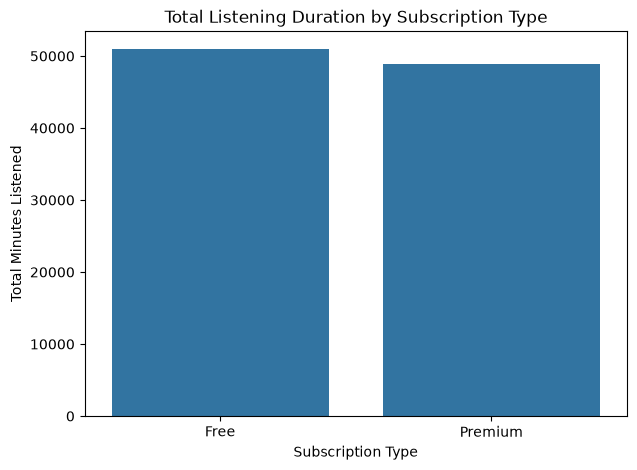

In [82]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=subscription_analysis.index,
    y=subscription_analysis["Total_Minutes"]
)

plt.title("Total Listening Duration by Subscription Type")
plt.xlabel("Subscription Type")
plt.ylabel("Total Minutes Listened")

plt.show()

20. Which countries have the highest Premium adoption? 

In [91]:
country_subscription = (
    users
    .groupby("Country")
    .agg(
        Total_Users=("User_ID", "nunique"),
        Premium_Users=("Subscription", lambda x: (x == "Premium").sum())
    )
    .reset_index()
)
print(country_subscription.head())

   Country  Total_Users  Premium_Users
0   Brazil          181             92
1   Canada          162             70
2  Germany          150             81
3    India          178             86
4       UK          168             79


In [92]:
engagement_analysis = (
    subscription_streams
    .groupby("Subscription")
    .agg(
        Total_Streams=("User_ID", "count"),
        Total_Minutes=("Minutes_Listened", "sum"),
        Average_Minutes_Per_Stream=("Minutes_Listened", "mean")
    )
    .round(2)
)

engagement_analysis

,Total_Streams,Total_Minutes,Average_Minutes_Per_Stream
Subscription,,,
Free,10131,50919,5.03
Premium,9869,48945,4.96


In [95]:
#Premium and Free users show different levels of listening engagement. 
# Premium users average 4.96 minutes per stream, compared with 5.03 minutes for Free users, 
# giving a difference of 0.07 minutes per stream.

difference = premium_avg - free_avg

print("Engagement difference:", round(difference, 2), "minutes")


Engagement difference: -0.07 minutes
